# Chapitre 6 - Cours 6 : moteurs de synchronisation, local-first et CRDT

Le cours 3 a présenté la réplication multi-leader entre régions. Poussée à l'extrême,
elle décrit aussi les applications qui fonctionnent **hors ligne** et celles qui
permettent la **collaboration en temps réel** : chaque appareil, voire chaque onglet de
navigateur, devient un leader. Ce cours, propre à la 2e édition, couvre la section *Sync
Engines and Local-First Software* et la partie *Automatic conflict resolution* /
*Conflict-free replicated datatypes and operational transformation* de *Dealing with
Conflicting Writes*. Le code est dans [`ddia/crdt.py`](../../ddia/crdt.py).

**Plan.**

1. Un leader par appareil : les moteurs de synchronisation.
2. Temps réel, hors ligne d'abord, local-first.
3. Avantages et limites d'un moteur de synchronisation.
4. CRDT : compteurs et ensembles qui convergent tout seuls.
5. Texte collaboratif : transformation opérationnelle contre CRDT.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import crdt
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Un leader par appareil (section *Sync Engines and Local-First Software*)

L'agenda de votre téléphone, de votre portable et de votre tablette doit rester
consultable **et modifiable** sans connexion ; les modifications faites hors ligne sont
synchronisées avec le serveur et les autres appareils au retour du réseau. Chaque
appareil a donc une **base locale qui accepte les écritures** (un leader), et une
réplication multi-leader asynchrone, la **synchronisation**, relie les répliques ; le
retard peut atteindre des heures ou des jours. C'est la configuration multi-régions du
cours 3 poussée à l'extrême : chaque appareil est une « région », reliée aux autres par
un réseau extrêmement peu fiable.

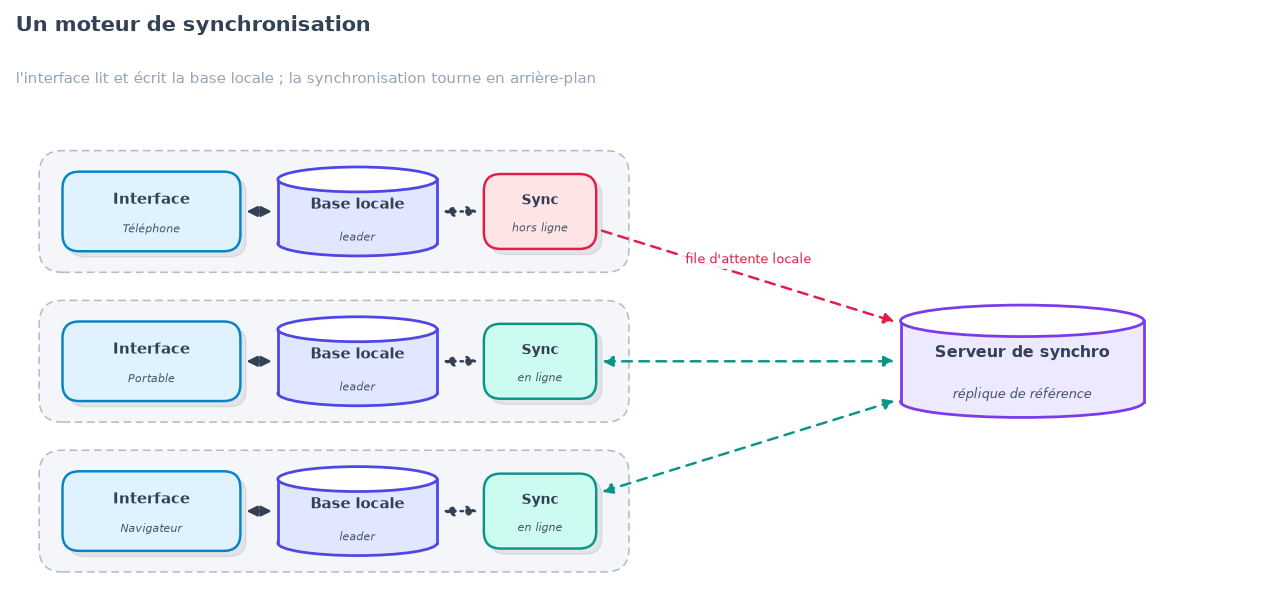

In [2]:
d = Diagram(13.5, 5.2, title="Un moteur de synchronisation",
            subtitle="l'interface lit et écrit la base locale ; la synchronisation tourne en arrière-plan")
for i, (nom, y, etat) in enumerate([("Téléphone", 4.0, "hors ligne"), ("Portable", 2.4, "en ligne"), ("Navigateur", 0.8, "en ligne")]):
    d.group(0.3, y - 0.65, 6.6, y + 0.65, None, color=SLATE)
    d.box(f"ui{i}", 1.5, y, "Interface", sub=nom, color=SKY, w=1.9, h=0.85, fontsize=9.5)
    d.box(f"db{i}", 3.7, y, "Base locale", sub="leader", color=INDIGO, kind="db", w=1.7, h=0.95, fontsize=9.5)
    d.box(f"se{i}", 5.65, y, "Sync", sub=etat, color=ROSE if etat == "hors ligne" else TEAL, w=1.2, h=0.8, fontsize=9)
    d.arrow(f"ui{i}", f"db{i}", both=True)
    d.arrow(f"db{i}", f"se{i}", both=True, style="dotted")
d.box("srv", 10.8, 2.4, "Serveur de synchro", sub="réplique de référence", color=VIOLET, kind="db", w=2.6, h=1.2)
d.arrow("se0", "srv", "file d'attente locale", style="dashed", color=ROSE)
d.arrow("se1", "srv", both=True, style="dashed", color=TEAL)
d.arrow("se2", "srv", both=True, style="dashed", color=TEAL)
d.show()

> **À retenir.** Une application qui doit fonctionner hors ligne est un système
> multi-leader : chaque appareil accepte des écritures et se synchronise plus tard,
> avec un retard potentiellement très long.

## 2. Temps réel, hors ligne d'abord, local-first (section *Real-time collaboration, offline-first, and local-first apps*)

Les applications collaboratives modernes (éditeurs de documents, de tableurs, de
graphismes, gestion de projets) affichent la saisie **immédiatement**, sans attendre un
aller-retour au serveur, et montrent les modifications des collaborateurs avec une faible
latence. C'est encore du multi-leader : chaque onglet ouvert sur le document est une
réplique, et les modifications sont répliquées de façon asynchrone. Même sans mode hors
ligne, le fait que chacun puisse modifier sans attendre de réponse du serveur suffit.

Vocabulaire :

- **moteur de synchronisation** (sync engine) : la bibliothèque qui capture les
  modifications locales, les envoie (ou les met en file si hors ligne), reçoit celles des
  autres, les fusionne dans la copie locale et met à jour l'interface ;
- **hors ligne d'abord** (offline-first) : une application qui continue de fonctionner
  hors ligne ;
- **local-first** : une application collaborative hors ligne d'abord, conçue pour
  continuer de fonctionner **même si son éditeur ferme tous ses services en ligne**, par
  exemple grâce à un protocole de synchronisation ouvert proposé par plusieurs
  hébergeurs. Git en est un exemple (sans temps réel) : on peut synchroniser via
  n'importe quel hébergeur.

**Pourquoi c'est si réactif.** Une écriture locale prend une fraction de milliseconde ;
une requête au serveur, un aller-retour réseau. Certaines applications visent à répondre
dans l'**image suivante** : 16 ms à 60 Hz. Comparons, avec des allers-retours typiques
(fibre, 4G, réseau mobile dégradé).

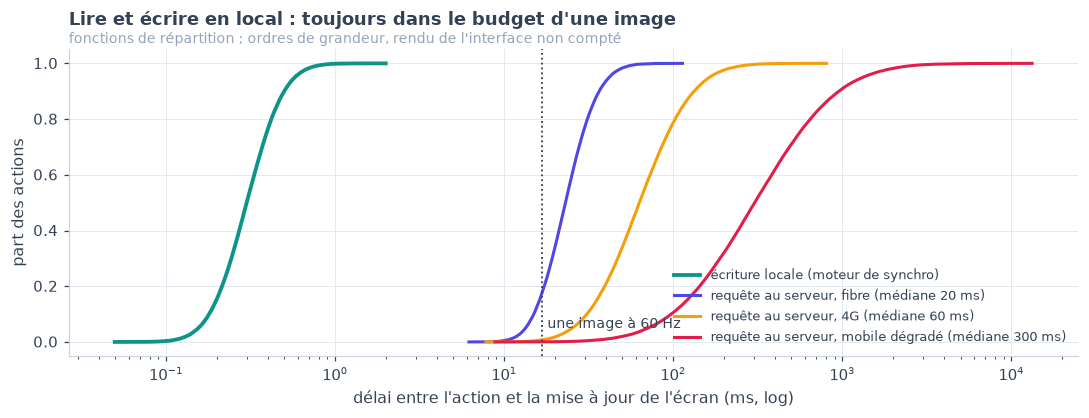

,local,fibre (médiane 20 ms),4G (médiane 60 ms),mobile dégradé (médiane 300 ms)
"% des actions sous 16,7 ms",100.0,17.4,0.7,0.0


In [3]:
N = 100000
local = rng.lognormal(np.log(0.3), 0.4, N)
reseaux = {"fibre (médiane 20 ms)": rng.lognormal(np.log(20), 0.4, N) + 3,
           "4G (médiane 60 ms)": rng.lognormal(np.log(60), 0.6, N) + 3,
           "mobile dégradé (médiane 300 ms)": rng.lognormal(np.log(300), 0.9, N) + 3}
fig, ax = plt.subplots(figsize=(10, 3.9))
ax.plot(np.sort(local), np.arange(1, N + 1) / N, color=TEAL, lw=2.5, label="écriture locale (moteur de synchro)")
for (k, v), c in zip(reseaux.items(), [INDIGO, AMBER, ROSE]):
    ax.plot(np.sort(v), np.arange(1, N + 1) / N, color=c, label=f"requête au serveur, {k}")
ax.axvline(16.7, color=SLATE, ls=":", lw=1.2); ax.text(18, 0.05, "une image à 60 Hz", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("délai entre l'action et la mise à jour de l'écran (ms, log)")
ax.set_ylabel("part des actions")
ax.set_title("Lire et écrire en local : toujours dans le budget d'une image")
subtitle(ax, "fonctions de répartition ; ordres de grandeur, rendu de l'interface non compté")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame({k: [100 * np.mean(v <= 16.7)] for k, v in {"local": local, **reseaux}.items()},
             index=["% des actions sous 16,7 ms"]).round(1)

Toutes les écritures locales tiennent dans le budget d'une image ; sur fibre, moins d'une
requête au serveur sur cinq y parvient, et pratiquement aucune en 4G. C'est l'argument central des moteurs de synchronisation :
la latence réseau sort du chemin critique de l'interface.

> **À retenir.** Collaboration en temps réel et fonctionnement hors ligne reposent sur
> la même infrastructure : une réplique locale qui accepte les écritures et un moteur de
> synchronisation ; local-first ajoute l'indépendance vis-à-vis d'un fournisseur.

## 3. Avantages et limites d'un moteur de synchronisation (section *Pros and cons of sync engines*)

Aujourd'hui, la plupart des applications web gardent très peu d'état sur le client et
interrogent le serveur à chaque besoin. Un moteur de synchronisation garde au contraire
un état **persistant** sur le client et relègue la communication en arrière-plan. Les
avantages listés par le livre :

- une interface bien plus réactive (section 2) ;
- pas de « mode hors ligne » séparé : **être hors ligne, c'est juste avoir un très grand
  délai réseau** ;
- un modèle de programmation plus simple : lire et écrire localement n'échoue presque
  jamais, alors que chaque appel de service exige une gestion d'erreur (chapitre
  5), d'où un style plus déclaratif ;
- combiné à une programmation réactive, un moyen naturel d'afficher en direct les
  modifications des autres.

Illustrons « hors ligne = grand délai » : un téléphone alterne périodes connectées et
déconnectées au cours d'une journée ; l'utilisateur fait des modifications à toute heure.
Chaque modification attend dans la file locale jusqu'à la prochaine connexion.

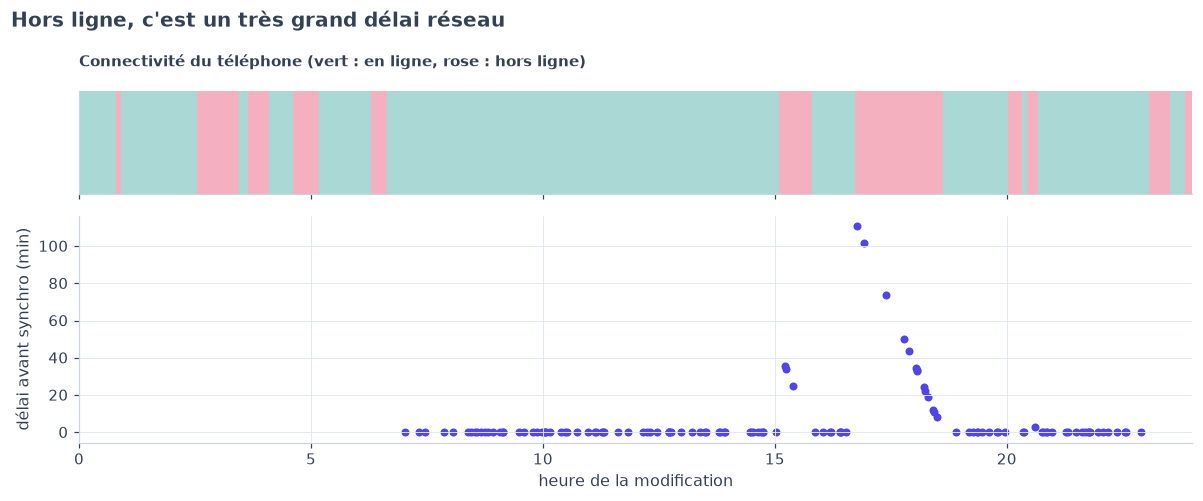

modifications synchronisées immédiatement : 85 % ; délai médian des autres : 33 min ; maximum : 111 min


In [4]:
heures = 24
t_mod = np.sort(rng.uniform(7, 23, 120))                       # 120 modifications entre 7 h et 23 h
bornes, t, connecte = [], 0.0, True
while t < heures:                                              # périodes alternées
    duree = rng.exponential(1.5 if connecte else 1.0)
    bornes.append((t, min(heures, t + duree), connecte))
    t += duree; connecte = not connecte
def prochaine_connexion(x):
    for a, b, c in bornes:
        if c and b > x:
            return max(a, x)
    return heures
delai = np.array([prochaine_connexion(x) - x for x in t_mod]) * 60
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.6), height_ratios=[1, 2.2], sharex=True)
for a, b, c in bornes:
    ax1.axvspan(a, b, color=TEAL if c else ROSE, alpha=0.35, lw=0)
ax1.set_yticks([]); ax1.grid(False); ax1.set_title("Connectivité du téléphone (vert : en ligne, rose : hors ligne)", fontsize=10)
ax2.scatter(t_mod, delai, s=18, color=INDIGO)
ax2.set_xlabel("heure de la modification"); ax2.set_ylabel("délai avant synchro (min)")
ax2.set_xlim(0, 24)
finish(fig, "Hors ligne, c'est un très grand délai réseau")
plt.show()
print(f"modifications synchronisées immédiatement : {np.mean(delai == 0) * 100:.0f} % ; "
      f"délai médian des autres : {np.median(delai[delai > 0]):.0f} min ; maximum : {delai.max():.0f} min")

La plupart des modifications (85 %) partent aussitôt, les autres attendent souvent une
demi-heure, parfois près de deux heures,
dans la file locale ; l'application, elle, a fonctionné exactement de la même façon dans
les deux cas. Le revers apparaît au cours 3 (section 4) : avec un délai $L$ de l'ordre de
l'heure, la probabilité de conflit $1 - e^{-\lambda L}$ n'est plus négligeable dès qu'une
donnée est partagée. D'où l'importance d'une fusion **automatique** (sections 4 et 5).

**La limite principale : la taille des données.** Un moteur de synchronisation marche
d'autant mieux que **toutes** les données utiles sont téléchargées à l'avance. C'est
raisonnable pour les documents d'un utilisateur, pas pour le catalogue entier d'un site
marchand. L'idée n'est pas neuve (Lotus Notes, dans les années 1980) ; on trouve
aujourd'hui des moteurs adossés à un service propriétaire (Firestore, Realm, Ditto) et
d'autres à un serveur libre, adaptés au local-first (PouchDB/CouchDB, Automerge, Yjs).
Les jeux vidéo multijoueurs ont un besoin voisin, le *netcode*, aux techniques trop
spécifiques pour être généralisées.

> **À retenir.** Un moteur de synchronisation rend l'interface rapide, unifie les modes
> connecté et hors ligne et simplifie le code client, mais suppose que les données d'un
> utilisateur tiennent sur son appareil et impose de fusionner des conflits.

## 4. CRDT : compteurs et ensembles (section *Conflict-free replicated datatypes and operational transformation*)

Un **CRDT** (conflict-free replicated datatype) est un type de données dont les copies
peuvent être modifiées indépendamment puis **fusionnées** de sorte que toutes convergent.
Dans la version « par état » utilisée ici, la fusion est une opération commutative,
associative et idempotente : peu importe l'ordre et le nombre de fois où deux répliques
échangent leurs états, elles convergent (cohérence à terme forte).

**Le compteur.** Chaque réplique compte ses propres incréments dans sa case ; la fusion
prend le maximum case par case ; la valeur est la somme (`crdt.GCounter`). Pour monter et
descendre, deux compteurs, l'un pour les incréments, l'autre pour les décréments
(`crdt.PNCounter`). Comparons avec deux fusions naïves sur un compteur de « j'aime »
modifié par cinq répliques qui se synchronisent au hasard (bavardage, ou *gossip*).

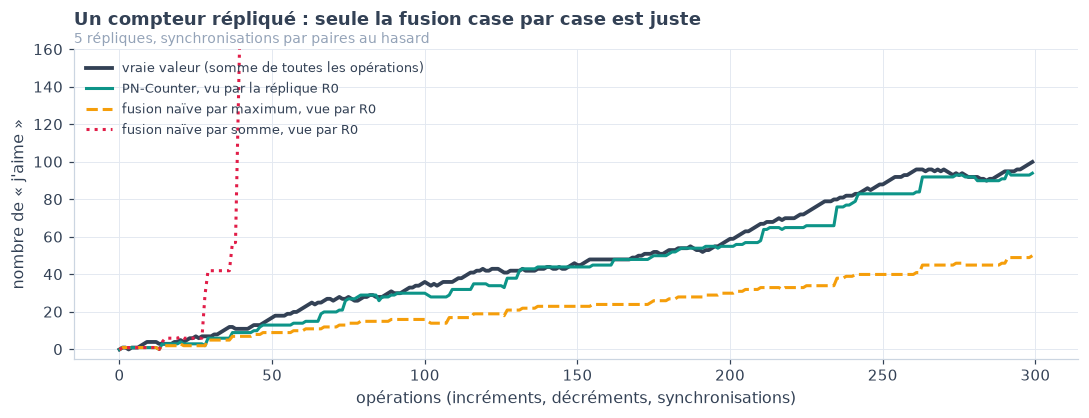

vraie valeur finale : 100 ; valeurs finales des 5 PN-Counter après synchronisation : {100}


In [5]:
def gossip(n_rep=5, n_ops=300, seed=0):
    rnd = random.Random(seed)
    pn = [crdt.PNCounter(f"R{i}") for i in range(n_rep)]
    naive_max = [0] * n_rep                  # fusion naïve : max des valeurs
    naive_sum = [0] * n_rep                  # fusion naïve : somme des valeurs
    vrai = 0
    histo = []
    for step in range(n_ops):
        i = rnd.randrange(n_rep)
        if rnd.random() < 0.6:
            delta = 1 if rnd.random() < 0.8 else -1
            vrai += delta
            (pn[i].inc if delta > 0 else pn[i].dec)()
            naive_max[i] += delta; naive_sum[i] += delta
        else:
            j = rnd.randrange(n_rep)
            pn[i].merge(pn[j]); pn[j].merge(pn[i])
            m = max(naive_max[i], naive_max[j]); naive_max[i] = naive_max[j] = m
            s_ = naive_sum[i] + naive_sum[j]; naive_sum[i] = naive_sum[j] = s_
        histo.append((vrai, pn[0].value, naive_max[0], naive_sum[0]))
    for i in range(n_rep):                   # synchronisation finale complète
        for j in range(n_rep):
            pn[i].merge(pn[j])
    return histo, vrai, {pn_.value for pn_ in pn}

histo, vrai, finaux = gossip()
H = np.array(histo)
fig, ax = plt.subplots(figsize=(10, 3.9))
ax.plot(H[:, 0], color=SLATE, lw=2.5, label="vraie valeur (somme de toutes les opérations)")
ax.plot(H[:, 1], color=TEAL, label="PN-Counter, vu par la réplique R0")
ax.plot(H[:, 2], color=AMBER, ls="--", label="fusion naïve par maximum, vue par R0")
ax.plot(H[:, 3], color=ROSE, ls=":", label="fusion naïve par somme, vue par R0")
ax.set_ylim(-5, max(H[:, 0].max(), H[:, 1].max()) * 1.6)
ax.set_xlabel("opérations (incréments, décréments, synchronisations)"); ax.set_ylabel("nombre de « j'aime »")
ax.set_title("Un compteur répliqué : seule la fusion case par case est juste")
subtitle(ax, "5 répliques, synchronisations par paires au hasard")
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()
print(f"vraie valeur finale : {vrai} ; valeurs finales des 5 PN-Counter après synchronisation : {finaux}")

La fusion par maximum **perd** des incréments (deux répliques qui ont chacune ajouté 3
donnent 3, pas 6) ; la fusion par somme **double compte** à chaque synchronisation et
s'envole (elle sort du graphique). Le PN-Counter, vu par une réplique, est en retard sur
la vraie valeur tant que les synchronisations ne lui ont pas tout apporté, mais **jamais
faux** ; après une synchronisation complète, les cinq répliques ont exactement la vraie
valeur.

**L'ensemble : réparer le panier d'Amazon.** L'`ORSet` (observed-remove set) étiquette
chaque ajout d'un identifiant unique ; une suppression ne retire que les étiquettes
qu'elle a **observées**. Les suppressions concurrentes du livre et du DVD sont toutes les
deux respectées ; et un ajout concurrent d'une suppression survit (« l'ajout gagne »),
parce que la suppression ne pouvait pas connaître son étiquette.

In [6]:
a, b = crdt.ORSet("appareil 1"), crdt.ORSet("appareil 2")
for x in ("savon", "livre", "dvd"):
    a.add(x)
b.merge(a)
a.remove("livre"); b.remove("dvd")                    # suppressions concurrentes
a.merge(b); b.merge(a)                                # synchronisation
etape1 = sorted(a.value)
a.add("dvd"); b.remove("savon")                       # ré-ajout du DVD sur 1, suppression du savon sur 2
a.merge(b); b.merge(a)
pd.DataFrame({"appareil 1": [etape1, sorted(a.value)], "appareil 2": [etape1, sorted(b.value)]},
             index=["après suppressions concurrentes (livre / dvd)", "après ré-ajout du dvd et retrait du savon"])

,appareil 1,appareil 2
après suppressions concurrentes (livre / dvd),[savon],[savon]
après ré-ajout du dvd et retrait du savon,[dvd],[dvd]


Le résultat attendu, {savon}, puis {dvd}, est obtenu sur les deux appareils : là où
l'union du cours 3 ressuscitait les articles et où les pierres tombales simples
empêchaient tout ré-ajout, l'OR-Set fait ce qu'on attend. **Vérifions la convergence**
par un test aléatoire : des répliques font des ajouts et suppressions au hasard, se
synchronisent dans des ordres aléatoires (avec doublons) ; à la fin, toutes doivent avoir
le même état.

In [7]:
def test_convergence(n_essais=300, seed=0):
    rnd = random.Random(seed)
    ok = 0
    for _ in range(n_essais):
        reps = [crdt.ORSet(f"R{i}") for i in range(4)]
        for _ in range(60):
            r = rnd.choice(reps)
            u = rnd.random()
            if u < 0.45:
                r.add(rnd.choice("abcdef"))
            elif u < 0.7 and r.value:
                r.remove(rnd.choice(sorted(r.value)))
            else:
                r.merge(rnd.choice(reps))
        ordre = [(i, j) for i in range(4) for j in range(4) if i != j] * 2
        rnd.shuffle(ordre)
        for i, j in ordre:
            reps[i].merge(reps[j])
        ok += len({frozenset(r.value) for r in reps}) == 1
    return ok / n_essais

print(f"essais où les 4 répliques convergent : {100 * test_convergence():.0f} %")

essais où les 4 répliques convergent : 100 %


Toutes les exécutions convergent. Les CRDT existent pour les compteurs, les ensembles,
les registres, les dictionnaires (fusion clé par clé), les listes et le texte ; on les
trouve dans des bases distribuées (Redis Enterprise, Riak, Azure Cosmos DB) et dans les
moteurs de synchronisation JSON (Automerge, Yjs). Leurs limites : ils ne savent pas
garantir un invariant global (une liste d'au plus cinq éléments), et ils traînent des
**métadonnées** (étiquettes, pierres tombales) qui grossissent avec l'historique.

> **À retenir.** Un CRDT fusionne par une opération commutative, associative et
> idempotente : toutes les répliques convergent quel que soit l'ordre des échanges, sans
> perdre d'opération (compteurs) ni ressusciter de suppression (OR-Set).

## 5. Texte collaboratif : transformation opérationnelle contre CRDT

Exemple du livre : deux répliques partent du texte « ice » ; l'une insère « n » au début
(« nice »), l'autre ajoute « ! » à la fin (« ice! »). Résultat attendu : « nice! ».

**Transformation opérationnelle (OT).** Les opérations désignent des **positions** :
insérer « n » en 0, insérer « ! » en 3. Appliquer naïvement « ! en 3 » sur « nice »
donnerait « nic!e ». Il faut **transformer** chaque opération en fonction des opérations
concurrentes déjà appliquées : l'insertion de « ! » devient une insertion en 4 parce
qu'un caractère a été inséré avant (`crdt.ot_transform`).

**CRDT de séquence.** Chaque caractère reçoit un **identifiant unique et immuable** (ici
un compteur et le nom de la réplique : i = 1A, c = 2A, e = 3A) ; on insère « après tel
identifiant » plutôt qu'« à telle position ». « ! » s'insère après 3A, « n » au début ;
des insertions concurrentes au même endroit sont départagées par leurs identifiants, de
la même façon partout. Aucune transformation n'est nécessaire (`crdt.RGA`).

In [8]:
A, B = [("ins", 0, "n", "A")], [("ins", 3, "!", "B")]
A2, B2 = crdt.ot_transform_seq(A, B)
naif = crdt.ot_apply(crdt.ot_apply("ice", A[0]), B[0])
ot_1 = crdt.ot_apply(crdt.ot_apply("ice", A[0]), B2[0])
ot_2 = crdt.ot_apply(crdt.ot_apply("ice", B[0]), A2[0])
ra, rb = crdt.RGA("A"), crdt.RGA("B")
rb.apply_all(ra.insert_text(0, "ice"))
op_n, op_ex = ra.insert(0, "n"), rb.insert(3, "!")
ra.apply(op_ex); rb.apply(op_n)
pd.DataFrame({
    "réplique A": [naif, f"{ot_1}  (« ! » transformé en {B2[0][:2]})", ra.text()],
    "réplique B": ["-", f"{ot_2}  (« n » reste {A2[0][:2]})", rb.text()],
}, index=["OT sans transformation", "OT avec transformation", "CRDT (identifiants)"])

,réplique A,réplique B
OT sans transformation,nic!e,-
OT avec transformation,"nice! (« ! » transformé en ('ins', 4))","nice! (« n » reste ('ins', 0))"
CRDT (identifiants),nice!,nice!


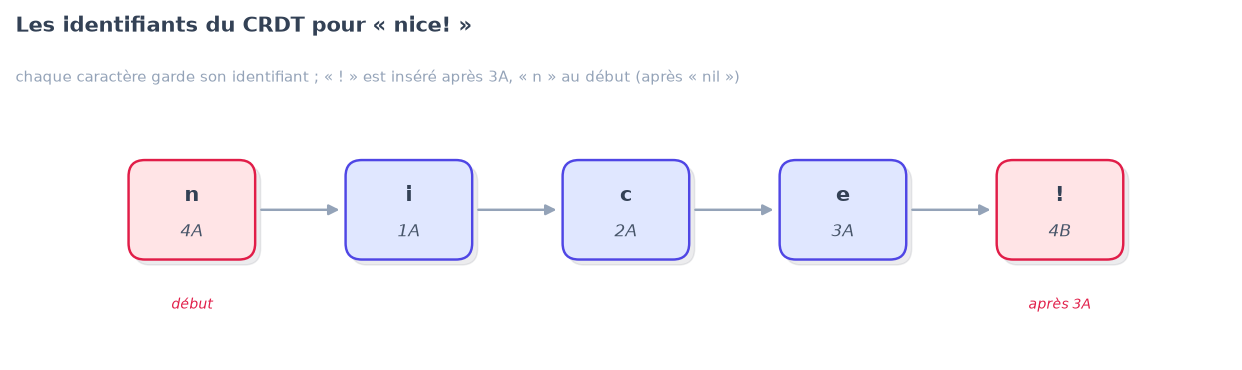

In [9]:
d = Diagram(13.5, 2.9, title="Les identifiants du CRDT pour « nice! »",
            subtitle="chaque caractère garde son identifiant ; « ! » est inséré après 3A, « n » au début (après « nil »)")
chars = [("n", "4A", "début"), ("i", "1A", None), ("c", "2A", None), ("e", "3A", None), ("!", "4B", "après 3A")]
for k, (ch, ident, rem) in enumerate(chars):
    x = 2.0 + 2.4 * k
    nouveau = rem is not None
    d.box(f"c{k}", x, 1.65, ch, sub=ident, color=ROSE if nouveau else INDIGO, w=1.4, h=1.1, fontsize=14, filled=False)
    if rem:
        d.note(x, 0.6, rem, color=ROSE)
for k in range(4):
    d.arrow(f"c{k}", f"c{k + 1}", color=GRAY)
d.show()

**Fuzzing de la convergence.** Les deux implémentations du module sont testées sur des
milliers d'éditions concurrentes aléatoires : trois répliques RGA éditent en se
synchronisant partiellement, puis reçoivent toutes les opérations dans un ordre aléatoire ;
deux sites OT produisent chacun une suite d'éditions concurrentes, transformées l'une par
rapport à l'autre.

In [10]:
def fuzz_rga(n_essais=200, seed=0):
    rnd = random.Random(seed)
    ok = 0
    for _ in range(n_essais):
        reps = [crdt.RGA(n) for n in "ABC"]
        ops = []
        for _ in range(40):
            r = rnd.choice(reps)
            t = r.text()
            if t and rnd.random() < 0.3:
                ops.append(r.delete(rnd.randrange(len(t))))
            else:
                ops.append(r.insert(rnd.randrange(len(t) + 1), rnd.choice("xyz")))
            if rnd.random() < 0.3:
                rnd.choice(reps).apply_all(r.log)
        for r in reps:
            sh = ops[:]; rnd.shuffle(sh); r.apply_all(sh)
        ok += len({r.text() for r in reps}) == 1
    return ok / n_essais

def fuzz_ot(n_essais=2000, seed=0):
    rnd = random.Random(seed)
    ok = 0
    for _ in range(n_essais):
        base = "".join(rnd.choice("abc") for _ in range(rnd.randint(0, 8)))
        def gen(site, txt):
            ops = []
            for _ in range(rnd.randint(1, 5)):
                if txt and rnd.random() < 0.4:
                    op = ("del", rnd.randrange(len(txt)))
                else:
                    op = ("ins", rnd.randrange(len(txt) + 1), rnd.choice("XYZ"), site)
                ops.append(op); txt = crdt.ot_apply(txt, op)
            return ops
        SA, SB = gen("A", base), gen("B", base)
        SA2, SB2 = crdt.ot_transform_seq(SA, SB)
        x = base
        for op in SA + SB2:
            x = crdt.ot_apply(x, op)
        y = base
        for op in SB + SA2:
            y = crdt.ot_apply(y, op)
        ok += x == y
    return ok / n_essais

pd.DataFrame({"essais convergents (%)": [100 * fuzz_rga(), 100 * fuzz_ot()]},
             index=["RGA, 3 répliques, ordres aléatoires", "OT, 2 sites, suites concurrentes"])

,essais convergents (%)
"RGA, 3 répliques, ordres aléatoires",100.0
"OT, 2 sites, suites concurrentes",100.0


**Le coût des métadonnées.** Un CRDT de texte garde un identifiant par caractère et une
pierre tombale pour chaque caractère supprimé. Simulons une session d'édition où l'on
tape et efface beaucoup : le texte visible reste court, la structure grossit.

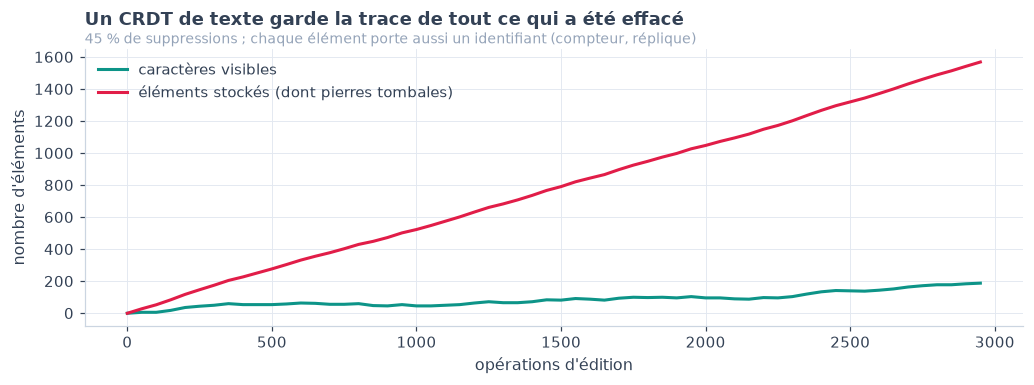

In [11]:
r = crdt.RGA("A")
rnd = random.Random(3)
mesures = []
for i in range(3000):
    t = r.text()
    if t and rnd.random() < 0.45:
        r.delete(rnd.randrange(len(t)))
    else:
        r.insert(rnd.randrange(len(t) + 1), "x")
    if i % 50 == 0:
        mesures.append((i, len(r.text()), len(r.elems)))
M = np.array(mesures)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(M[:, 0], M[:, 1], color=TEAL, label="caractères visibles")
ax.plot(M[:, 0], M[:, 2], color=ROSE, label="éléments stockés (dont pierres tombales)")
ax.set_xlabel("opérations d'édition"); ax.set_ylabel("nombre d'éléments")
ax.set_title("Un CRDT de texte garde la trace de tout ce qui a été effacé")
subtitle(ax, "45 % de suppressions ; chaque élément porte aussi un identifiant (compteur, réplique)")
ax.legend()
plt.tight_layout(); plt.show()

Après 3 000 opérations, le texte visible fait quelques centaines de caractères mais la
structure en garde plusieurs fois plus. Les implémentations réelles compressent
fortement ces métadonnées. OT n'a pas ce surcoût mais suppose en pratique un serveur
central qui ordonne les opérations (c'est le choix des éditeurs de documents en ligne,
avec la bibliothèque ShareDB côté JSON) ; les CRDT n'ont pas besoin de serveur
(Automerge, Yjs), ce qui convient au local-first. Les deux familles ont leurs compromis,
et des algorithmes récents combinent leurs avantages.

> **À retenir.** OT transforme les positions des opérations concurrentes ; un CRDT de
> séquence donne à chaque caractère un identifiant immuable et n'a rien à transformer.
> Les deux convergent ; OT s'appuie volontiers sur un serveur, le CRDT paie en
> métadonnées son indépendance.

## Synthèse

- Hors ligne et collaboration en temps réel sont deux visages de la réplication
  multi-leader : chaque appareil est un leader, le moteur de synchronisation réplique en
  arrière-plan, et être hors ligne n'est qu'un très grand délai.
- Les moteurs de synchronisation rendent l'interface instantanée et simplifient le code
  client ; ils supposent que les données d'un utilisateur tiennent sur son appareil.
- Les CRDT (compteurs, OR-Set, séquences) et la transformation opérationnelle fusionnent
  automatiquement les écritures concurrentes en garantissant la convergence.

Liens : la détection de la concurrence (cours 5) fournit le cadre ; les conflits qui
portent sur des invariants globaux restent hors de portée des CRDT (cours 3, section 9,
et chapitre 13).